In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv('bank_full.csv', sep = ';')

In [9]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [11]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [12]:
df.shape

(45211, 17)

In [13]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [14]:
df['campaign'].value_counts()

campaign
1     17544
2     12505
3      5521
4      3522
5      1764
6      1291
7       735
8       540
9       327
10      266
11      201
12      155
13      133
14       93
15       84
16       79
17       69
18       51
19       44
20       43
21       35
22       23
23       22
25       22
24       20
29       16
28       16
26       13
31       12
27       10
32        9
30        8
33        6
34        5
36        4
35        4
38        3
43        3
41        2
50        2
37        2
55        1
51        1
63        1
46        1
58        1
39        1
44        1
Name: count, dtype: int64

In [15]:
df['pdays'].value_counts()

pdays
-1      36954
 182      167
 92       147
 183      126
 91       126
        ...  
 756        1
 745        1
 530        1
 749        1
 838        1
Name: count, Length: 559, dtype: int64

In [16]:
df['poutcome'].value_counts()

poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

In [17]:
df['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
for i in ['job', 'education', 'contact', 'poutcome']:
    print(i, df[i].value_counts().get('unknown', 0))

job 288
education 1857
contact 13020
poutcome 36959


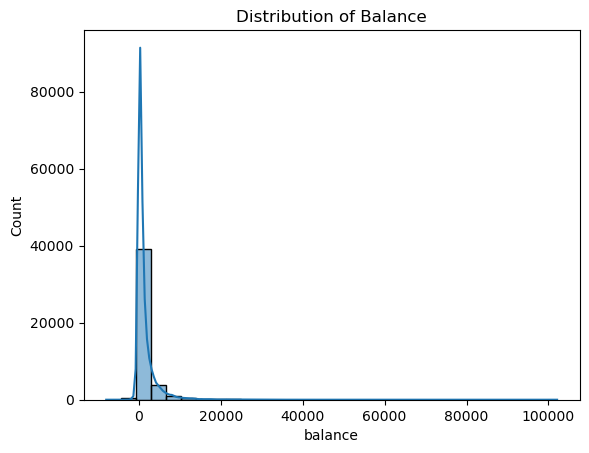

In [20]:
sns.histplot(df['balance'], bins = 30, kde = True)
plt.title('Distribution of Balance')
plt.show()

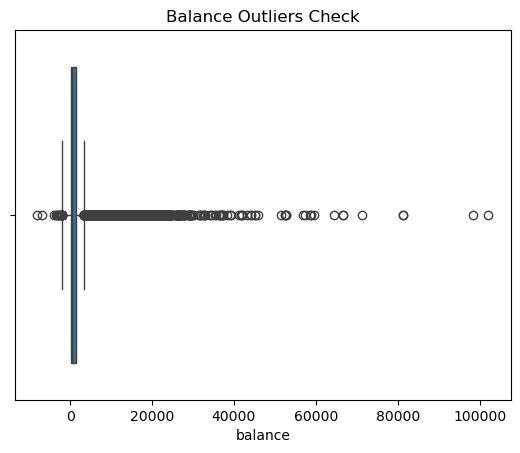

In [21]:
sns.boxplot(x = df['balance'])
plt.title('Balance Outliers Check')
plt.show()

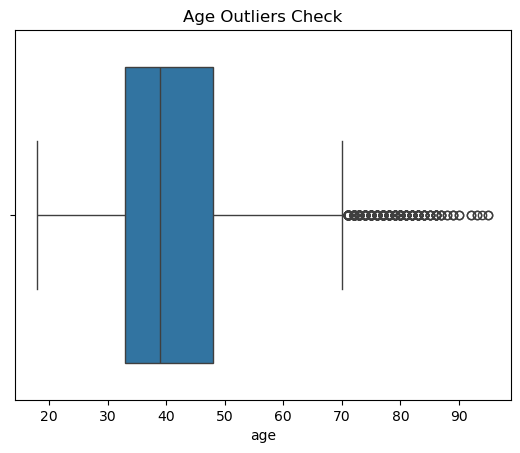

In [22]:
sns.boxplot(x=df['age'])
plt.title('Age Outliers Check')
plt.show()

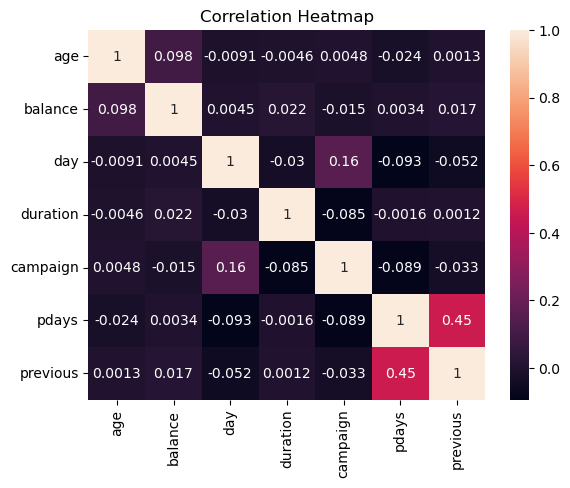

In [23]:
sns.heatmap(df.corr(numeric_only = True), annot = True)
plt.title('Correlation Heatmap')
plt.show()

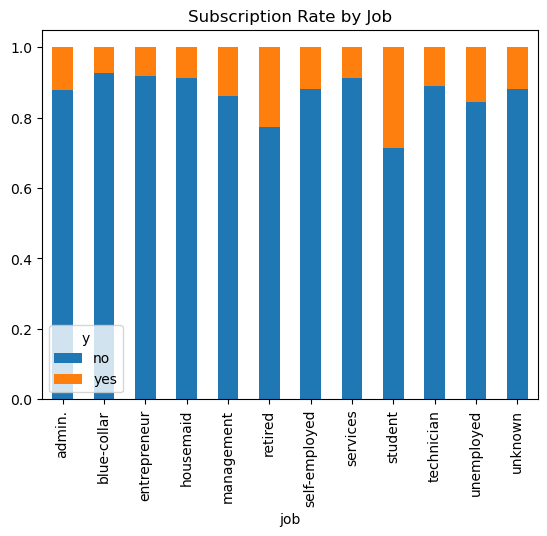

In [24]:
df.groupby('job')['y'].value_counts(normalize=True).unstack().plot(kind='bar', stacked=True)
plt.title('Subscription Rate by Job')
plt.show()

In [25]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus

In [26]:
#mysql connection
username = 'root'
password = quote_plus('root@123')
host = 'localhost'
port = '3306'
database = 'marketdatabase'

engine = create_engine(f"mysql+pymysql://{username}:{password}@{host}:{port}/{database}")

#write datafram to mysql
table_name = 'marketing'
df.to_sql(table_name, engine, if_exists = 'replace', index = False)

#read back sample
pd.read_sql('SELECT * FROM marketing LIMIT 5;', engine)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
